# Data analysis notebook for "Sound and Efficient Certification of High-Quality Qubit Operations: Theory and Experiment"

This is a concise notebook that perform analysis of the experimental data according to the certification methods described in the paper and produces the quality metrics reported in Table I. For a more general certification suit, see [GitHub page](https://github.com/QC-TUDa/QSQlab).

The data is analyzed in the following order:
- The experimental counts are collected (pooled) from the JSONL file.
- Probabilities $\mathbb{P}[0|n]$, and quantities $\varepsilon_n = 1-(-1)^{n/2}\bigl(\mathbb{P}[0\mid n]-\mathbb{P}[0\mid n+2]\bigr)$ are estimated with their confidence intervals.
- The signal $\varepsilon_n$ as a function of $n$ is plotted.
- The quantity $\sqrt{\varepsilon_0}+\sqrt{\varepsilon_2}$, which determines whether the implementation of $\sqrt{\mathrm{X}}$-gate is in the high-quality regime, is calculated.
- The lower bound on the average gate fidelity from the short-sequence analysis as well as the fidelity for the preparation state and total variation distance for the measurement, according to Theorem 1 in the Methods are calculated.
- Available parameters $j$ and $\ell$ from Lemmas 4 and 5, respectively, are listed.
- Given $j$, the bound on the phase of $\lambda$ is calculated according to Lemma 4. The required initial trust $\vert \theta-\frac{\pi}{2}\vert \leq \eta$ in the phase value is calculated.
- Given $\ell$, the (simplified) bound in Lemma 5 is calculated.
- Finally, the lower bound on the average gate fidelity based on the long-sequence analysis (Lemma 3 and Eq.(19)) is calculated.

All the estimates are reported together with the corresponding confidence intervals. The exact Clopper–Pearson intervals for the probabilities are propagated to other quality metrics, each with the resulting $1-\delta$ confidence level via Bonferroni allocation.

*This code was developed with assistance from ChatGPT (OpenAI). The corresponding author reviewed and validated the generated code and takes full responsibility for its correctness. 15 August 2026.*

In [83]:
# Import the libraries
from pathlib import Path
import json
import math
from collections.abc import Iterable, Mapping
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import beta
from IPython.display import Markdown, display

In [ ]:
# Set the path to the data, and the confidence level for the analysis
# DATA_PATH = Path('./red_trap/18.07/RT_1ms_7pm.jsonl') # used to place initial trust on the phase (as in Lemma 4)
DATA_PATH = Path('./red_trap/23.07/RT_1ms_3pm.jsonl')
# DATA_PATH = Path('./red_trap/23.07/RT_0.5ms_6pm.jsonl')
CONFIDENCE = 0.99

### Define basic helper functions first for loading the data, calculating $\varepsilon_n$, and confidence intervals

In [85]:
# Define a function to collect (pool) data from the input JSONL file
def load_and_pool_jsonl(path: str | Path) -> pd.DataFrame:
    """Pool zero counts and total shots over records with equal n."""
    rows = []
    with Path(path).expanduser().open(encoding='utf-8') as handle:
        for line in handle:
            if line.strip():
                record = json.loads(line)
                counts = record['counts']
                rows.append(
                    {
                        'n': int(record['amount_of_gates']),
                        'zero_count': int(counts.get('0', 0)),
                        'shots': sum(int(value) for value in counts.values()),
                    }
                )
    pooled = (
        pd.DataFrame(rows)
        .groupby('n', sort=True)
        .agg(
            zero_count=('zero_count', 'sum'),
            shots=('shots', 'sum'),
            records=('n', 'size'),
        )
    )
    pooled['p0_hat'] = pooled['zero_count'] / pooled['shots']
    return pooled

# Define functions for calculating epsilon, available indices for epsilon, a mapping of indices for epsilon and P[0|n], and the confidence intervals.
def epsilon(n: int, probabilities: Mapping[int, float]) -> float:
    return float(
        1 - (-1) ** (n // 2) * (probabilities[n] - probabilities[n + 2])
    )

def available_epsilon_indices(pooled: pd.DataFrame) -> list[int]:
    available_n = set(map(int, pooled.index))
    return sorted(
        n for n in available_n if n % 2 == 0 and n + 2 in available_n
    )

# Define functions for calculating the Clopper-Pearson confidence interval and the Bonferroni box
def clopper_pearson(
    successes: int, trials: int, confidence: float
) -> tuple[float, float]:
    """Exact equal-tailed interval for one binomial probability."""
    alpha = 1.0 - confidence
    lower = (
        0.0
        if successes == 0
        else float(beta.ppf(alpha / 2, successes, trials - successes + 1))
    )
    upper = (
        1.0
        if successes == trials
        else float(beta.ppf(1 - alpha / 2, successes + 1, trials - successes))
    )
    return lower, upper

def bonferroni_box(
    pooled: pd.DataFrame,
    probability_indices: Iterable[int],
    confidence: float,
) -> tuple[dict[int, tuple[float, float]], float]:
    """CP probability box with joint coverage at least confidence."""
    indices = sorted(set(probability_indices))
    per_probability_confidence = 1 - (1 - confidence) / len(indices)
    intervals = {
        n: clopper_pearson(
            int(pooled.loc[n, 'zero_count']),
            int(pooled.loc[n, 'shots']),
            per_probability_confidence,
        )
        for n in indices
    }
    return intervals, per_probability_confidence

def epsilon_interval(
    n: int, probability_box: Mapping[int, tuple[float, float]]
) -> tuple[float, float]:
    """Exact range of epsilon_n over a rectangular probability box."""
    sign = (-1) ** (n // 2)
    p_n_low, p_n_high = probability_box[n]
    p_next_low, p_next_high = probability_box[n + 2]
    if sign == 1:
        return 1 - p_n_high + p_next_low, 1 - p_n_low + p_next_high
    return 1 + p_n_low - p_next_high, 1 + p_n_high - p_next_low

# Define a function to produce a short-hand notation for the reported values with their confidence intervals
def compact_parenthetical(
    estimate: float,
    lower: float,
    upper: float,
    scale: float = 1.0,
    suffix: str = '',
) -> str:
    """Symmetric shorthand that conservatively encloses an asymmetric interval."""
    if not all(math.isfinite(x) for x in (estimate, lower, upper)):
        return 'not certified'
    center = scale * estimate
    low = scale * lower
    high = scale * upper
    error = max(center - low, high - center)
    if error == 0:
        return f'{center:.10g}{suffix}'
    exponent = min(math.floor(math.log10(error)), 0) # here it's assume that the error is less than 1.
    while True:
        unit = 10.0**exponent
        rounded_center = round(center / unit) * unit
        required_error = max(rounded_center - low, high - rounded_center)
        digit = math.ceil(required_error / unit - 1e-12)
        if digit <= 9 or exponent == 0:
            break
        exponent += 1
    decimals = max(0, -exponent)
    return f'{rounded_center:.{decimals}f}({digit}){suffix}'

## Output the collected counts, plot the signal $\varepsilon_n$

### Pooled counts

,zero_count,shots,records,p0_hat
n,,,,
0,29831,30000,30,0.994367
2,76,30000,30,0.002533
4,29770,30000,30,0.992333
6,299,30000,30,0.009967
8,30461,31000,31,0.982613
10,19,1000,1,0.019000
14,43,1000,1,0.043000
16,947,1000,1,0.947000
20,924,1000,1,0.924000


### $\epsilon_n$ with individual 99% intervals

,epsilon estimate,confidence lower,confidence upper,lower error,upper error
n,,,,,
0,0.008167,0.006290,0.010421,0.001877,0.002255
2,0.010200,0.008122,0.012654,0.002078,0.002454
4,0.017633,0.014759,0.020879,0.002874,0.003245
6,0.027354,0.023806,0.031263,0.003548,0.003909
8,0.036387,0.024440,0.054149,0.011947,0.017762
14,0.096000,0.062223,0.140204,0.033777,0.044204


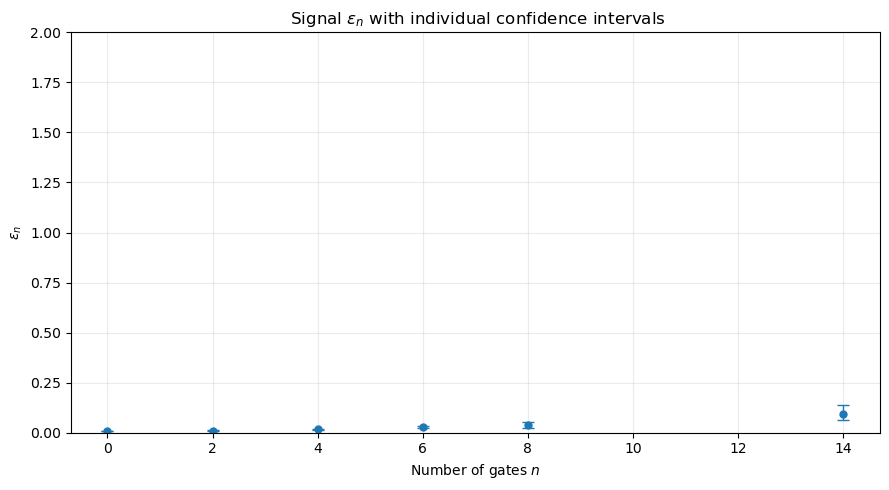

In [86]:
pooled = load_and_pool_jsonl(DATA_PATH)
p_hat = pooled['p0_hat'].astype(float).to_dict()
epsilon_indices = available_epsilon_indices(pooled)

epsilon_rows = []
for n in epsilon_indices:
    probability_box, component_confidence = bonferroni_box(
        pooled, [n, n + 2], CONFIDENCE
    )
    estimate = epsilon(n, p_hat)
    lower, upper = epsilon_interval(n, probability_box)
    epsilon_rows.append(
        {
            'n': n,
            'epsilon estimate': estimate,
            'confidence lower': lower,
            'confidence upper': upper,
            'lower error': estimate - lower,
            'upper error': upper - estimate,
        #    'CP confidence per probability': component_confidence,
        }
    )

epsilon_table = pd.DataFrame(epsilon_rows).set_index('n')

display(Markdown('### Pooled counts'))
display(pooled)
display(Markdown(f'### $\\epsilon_n$ with individual {100 * CONFIDENCE:g}% intervals'))
display(epsilon_table)

x = epsilon_table.index.to_numpy(dtype=float)
y = epsilon_table['epsilon estimate'].to_numpy()
yerr = np.vstack(
    [
        epsilon_table['lower error'].to_numpy(),
        epsilon_table['upper error'].to_numpy(),
    ]
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(
    x,
    y,
    yerr=yerr,
    fmt='o',
    markersize=5,
    linewidth=1,
    elinewidth=1,
    capsize=4,
)
ax.set_xlabel(r'Number of gates $n$')
ax.set_ylabel(r'$\epsilon_n$')
ax.set_title(
    rf' Signal $\epsilon_n$ with individual confidence intervals'
)
ax.grid(alpha=0.25)
ax.set_ylim(0, 2)
fig.tight_layout()
plt.show()

## Now perform short-sequence analysis

In [87]:
# Define a function to perform short sequence analysis, calculating the high-fidelity condition and short-sequence fidelity based on the pooled data and confidence level.
def short_sequence_analysis(pooled: pd.DataFrame, confidence: float) -> dict[str, pd.DataFrame]:
    p_hat = pooled['p0_hat'].astype(float).to_dict()

    # High-fidelity condition from eps_0 and eps_2
    short_keys = [0, 2, 4]
    box_1, cp_1 = bonferroni_box(pooled, short_keys, confidence)
    e0_hat, e2_hat = epsilon(0, p_hat), epsilon(2, p_hat)
    e0_low, e0_high = epsilon_interval(0, box_1)
    e2_low, e2_high = epsilon_interval(2, box_1)
    sum_hat = math.sqrt(e0_hat) + math.sqrt(e2_hat)
    sum_low = math.sqrt(max(0, e0_low)) + math.sqrt(max(0, e2_low))
    sum_high = math.sqrt(e0_high) + math.sqrt(e2_high)
    hf_condition = pd.DataFrame([
        {
            "estimate": sum_hat,
            "confidence lower": sum_low,
            "confidence upper": sum_high,
            "short-hand notation": compact_parenthetical(
                sum_hat, sum_low, sum_high
            ),
        }
    ])
    # Short-sequence fidelity
    def short_fidelity(value: float) -> float:
        return 1 / 3 + 2 / 3 * math.sqrt(1 - value**2)

    fidelity_hat = short_fidelity(sum_hat) if sum_hat <= 1 else math.nan
    if sum_hat <= 1:
        fidelity_low = short_fidelity(sum_high)
        fidelity_high = short_fidelity(sum_low)
    else:
        fidelity_low = fidelity_high = math.nan
    short_sequence_fid = pd.DataFrame([
        {
            "estimate": fidelity_hat,
            "confidence lower": fidelity_low,
            "confidence upper": fidelity_high,
            "short-hand notation": compact_parenthetical(
                fidelity_hat,
                fidelity_low,
                fidelity_high,
                100,
                " %",
            ),
        }
    ])
    return {
        "high-fidelity condition": hf_condition,
        "short-sequence fidelity": short_sequence_fid,
    }

In [88]:
# Calculate and display the short-sequence analysis results
short_sequence_report = short_sequence_analysis(pooled, CONFIDENCE)
confidence_label = f'{100 * CONFIDENCE:g}%'
display(Markdown(f'### High-fidelity regime sum condition (must be below 0.5): ({confidence_label} confidence)'))
display(short_sequence_report['high-fidelity condition'].style.hide(axis="index"))

display(Markdown(f'### Average gate fidelity based on short-sequence data ({confidence_label} confidence)'))
display(short_sequence_report['short-sequence fidelity'].style.hide(axis="index"))

### High-fidelity regime sum condition (must be below 0.5): (99% confidence)

estimate,confidence lower,confidence upper,short-hand notation
0.191365,0.168470,0.215637,0.19(3)


### Average gate fidelity based on short-sequence data (99% confidence)

estimate,confidence lower,confidence upper,short-hand notation
0.987679,0.984316,0.990471,98.8(4) %


## Now perform long-sequence analysis
First, find available parameters $j$ (with $i$, see the discussion after Lemma 4), and $\ell$.

In [89]:
# Define some helper functions
def epsilon_probability_indices(epsilon_indices: Iterable[int]) -> list[int]:
    return sorted({k for n in epsilon_indices for k in (n, n + 2)})

def phase_candidates(epsilon_indices: Iterable[int]) -> list[tuple[int, int]]:
    """All supported even i and odd j."""
    epsilon_indices = sorted(set(epsilon_indices))
    epsilon_set = set(epsilon_indices)
    largest = max(epsilon_indices)
    candidates = []
    for i in epsilon_indices:
        for j in range(1, (largest - i) // 6 + 1, 2):
            required = {i, i + 2 * j, i + 4 * j, i + 6 * j}
            if required <= epsilon_set:
                candidates.append((i, j))
    return candidates

### Available parameter choices

In [90]:
available_phase_pairs = phase_candidates(epsilon_indices)
phase_pairs_table = pd.DataFrame(
    [
        {
            'i': i,
            'j': j,
            'required epsilon indices': (i, i + 2*j, i + 4*j, i + 6*j),
        }
        for i, j in available_phase_pairs
    ]
)

available_l = [n for n in epsilon_indices if n >= 22]
l_candidates_table = pd.DataFrame(
    [
        {
            'l': ell,
            'required probability depths': (ell, ell + 2),
            '|1-epsilon_l| estimate': abs(1 - epsilon(ell, p_hat)),
            'point condition >= 0.7': abs(1 - epsilon(ell, p_hat)) >= 0.7,
        }
        for ell in available_l
    ]
)

display(Markdown('### Available $(i,j)$ pairs'))
if phase_pairs_table.empty:
    display(Markdown('No suitable candidates'))
else:
    display(phase_pairs_table.style.hide(axis="index"))
display(Markdown('### Available $l$ values. Only use those with $|1-\\epsilon_l| \\geq 0.7$.'))
if l_candidates_table.empty:
    display(Markdown('No suitable candidates'))
else:
    display(l_candidates_table.style.hide(axis="index"))

### Available $(i,j)$ pairs

i,j,required epsilon indices
0,1,"(0, 2, 4, 6)"
2,1,"(2, 4, 6, 8)"


### Available $l$ values. Only use those with $|1-\epsilon_l| \geq 0.7$.

No suitable candidates

### Choose $(i,j)$ and $\ell$ parameters, and define the functions for the long-sequence analysis.

In [91]:
# The following are the choices made in the paper for the different datasets.
#  for 18.07/RT_1ms_7pm.jsonl, there is no suitable l (hence set l=0). 
# This data is used to produce an initial trust for the phase from the xi-based bound. 
if DATA_PATH.name == 'RT_1ms_7pm.jsonl':
    i = 0
    j = 1
    l = 0
elif DATA_PATH.name == 'RT_1ms_3pm.jsonl': 
    i = 0
    j = 25
    l = 250
elif DATA_PATH.name == 'RT_0.5ms_6pm.jsonl':
    i = 0
    j = 25
    l = 104
else:
    raise ValueError(f'Data is not among the ones used in the paper. Please make a choice of i,j and l from the available candidates.')


# Define a function to evaluate xi after sorting the four epsilon values.
def ordered_phase_point(
    p_hat: Mapping[int, float], i: int, j: int
) -> dict[str, object]:
    """Evaluate xi after sorting the four epsilon values."""
    indices = (i, i + 2 * j, i + 4 * j, i + 6 * j)
    raw_pairs = tuple((n, epsilon(n, p_hat)) for n in indices)
    ordered_pairs = tuple(sorted(raw_pairs, key=lambda item: item[1]))
    e0, e1, e2, e3 = (value for _, value in ordered_pairs)

    result = {
        'epsilon indices': indices,
        'ordered epsilon values': (e0, e1, e2, e3),
        'xi': math.nan,
        'phase': math.nan,
        'eta_max': math.nan,
        '|lambda| xi bound': math.nan,
        'status': 'ok',
    }

    if e3 > 1:
        result['status'] = 'largest ordered epsilon > 1'
        return result

    xi = math.sqrt(max(0.0, e3 + e2 - e1 - e0) / (1 - e1))
    result['xi'] = xi
    if xi > 1:
        result['status'] = 'xi > 1, so arcsin(xi) is not defined'
        return result

    angle = math.asin(xi)
    result['phase'] = angle / (2 * j)
    result['eta_max'] = (2 * math.pi - angle) / (2 * j)
    result['|lambda| xi bound'] = (1 - xi) ** (1 / (2 * j))
    return result

# Define a function to compute the conservative ranges for the four epsilon from the phase bound
def ordered_epsilon_ranges(
    epsilon_indices: Iterable[int],
    probability_box: Mapping[int, tuple[float, float]],
) -> tuple[np.ndarray, np.ndarray]:
    """Conservative ranges for the four epsilon order statistics."""
    raw_ranges = [epsilon_interval(n, probability_box) for n in epsilon_indices]
    ordered_lower = np.sort([lower for lower, _ in raw_ranges])
    ordered_upper = np.sort([upper for _, upper in raw_ranges])
    return ordered_lower, ordered_upper

# Define a function to calculate the confidence interval for the phase estimate
def phase_result(
    p_hat: Mapping[int, float],
    probability_box: Mapping[int, tuple[float, float]],
    i: int,
    j: int,
) -> dict[str, object]:
    """Propagate one joint CP probability box through the sorted formula."""
    point = ordered_phase_point(p_hat, i, j)
    lower, upper = ordered_epsilon_ranges(
        point['epsilon indices'], probability_box
    )
    a_low, b_low, c_low, d_low = lower
    a_high, b_high, c_high, d_high = upper

    result = dict(point)
    result.update(
        {
            'ordered epsilon lower': tuple(lower),
            'ordered epsilon upper': tuple(upper),
            'xi lower': math.nan,
            'xi upper': math.nan,
            'phase lower': math.nan,
            'phase upper': math.nan,
            'eta_max lower': math.nan,
            'eta_max upper': math.nan,
            '|lambda| xi bound lower': math.nan,
            '|lambda| xi bound upper': math.nan,
            'confidence status': 'ok',
        }
    )

    if d_high > 1:
        result['confidence status'] = 'largest ordered epsilon <= 1 is not certified'
        return result

    numerator_low = max(0.0, d_low + c_low - b_high - a_high)
    numerator_high = max(0.0, d_high + c_high - b_low - a_low)
    denominator_low = 1 - b_high
    denominator_high = 1 - b_low
    xi_low = math.sqrt(numerator_low / denominator_high)
    xi_high = math.sqrt(numerator_high / denominator_low)
    result['xi lower'] = xi_low
    result['xi upper'] = xi_high

    if xi_high > 1:
        result['confidence status'] = (
            'arcsin domain is not certified because xi upper > 1'
        )
        return result

    result['phase lower'] = math.asin(xi_low) / (2 * j)
    result['phase upper'] = math.asin(xi_high) / (2 * j)
    result['eta_max lower'] = (2 * math.pi - math.asin(xi_high)) / (2 * j)
    result['eta_max upper'] = (2 * math.pi - math.asin(xi_low)) / (2 * j)
    result['|lambda| xi bound lower'] = (1 - xi_high) ** (1 / (2 * j))
    result['|lambda| xi bound upper'] = (1 - xi_low) ** (1 / (2 * j))
    return result

# Define a function to calculate the amplitude bound
def amplitude_result(
    p_hat: Mapping[int, float],
    probability_box: Mapping[int, tuple[float, float]],
    ell: int,
) -> dict[str, object]:
    epsilon_hat = epsilon(ell, p_hat)
    epsilon_low, epsilon_high = epsilon_interval(ell, probability_box)
    distance_hat = abs(1 - epsilon_hat)
    distance_low = (
        0.0
        if epsilon_low <= 1 <= epsilon_high
        else min(abs(1 - epsilon_low), abs(1 - epsilon_high))
    )
    distance_high = max(abs(1 - epsilon_low), abs(1 - epsilon_high))
    exponent = 1 / (ell - 11)
    estimate = distance_hat**exponent

    if distance_low >= 0.7:
        lower = distance_low**exponent
        upper = distance_high**exponent
        status = 'ok'
    else:
        lower = upper = math.nan
        status = '|1 - epsilon_l| >= 0.7 is not certified'

    return {
        'l': ell,
        'epsilon estimate': epsilon_hat,
        'epsilon lower': epsilon_low,
        'epsilon upper': epsilon_high,
        '|1-epsilon_l| estimate': distance_hat,
        '|1-epsilon_l| lower': distance_low,
        '|1-epsilon_l| upper': distance_high,
        '|lambda| estimate': estimate,
        '|lambda| lower': lower,
        '|lambda| upper': upper,
        'status': status,
    }

# Define a function to calculate the long-sequence fidelity based on the amplitude and phase bounds
def long_fidelity(lambda_abs: float, phase_deviation: float) -> float:
    return 1 / 3 + lambda_abs * (1 + math.cos(phase_deviation)) / 3


# Finally, define a function to perform long sequence analysis
def long_sequence_analysis(
    pooled: pd.DataFrame,
    i: int,
    j: int,
    ell: int,
    confidence: float,
    ) -> dict[str, pd.DataFrame]:
    p_hat = pooled['p0_hat'].astype(float).to_dict()
    phase_epsilon_indices = (i, i + 2 * j, i + 4 * j, i + 6 * j)
    phase_keys = epsilon_probability_indices(phase_epsilon_indices)

    # Phase results
    phase_box, _ = bonferroni_box(pooled, phase_keys, confidence)
    phase = phase_result(p_hat, phase_box, i, j)
    eta_condition = (
        f"eta < {phase['eta_max lower']:.10g} rad"
        if math.isfinite(phase['eta_max lower'])
        else 'not certified'
    )
    phase_certificate = pd.DataFrame([
        {
            "i":i,
            "j":j,
            "phase estimate [rad]": phase['phase'],
            "phase lower [rad]": phase['phase lower'],
            "phase upper [rad]": phase['phase upper'],
            "eta_max estimate [rad]": phase['eta_max'],
            "eta_max lower [rad]": phase['eta_max lower'],
            "eta_max upper [rad]": phase['eta_max upper'],
            "required initial-trust condition": eta_condition,
            "status": phase['confidence status'],
            "short-hand notation": compact_parenthetical(
                phase['phase'],
                phase['phase lower'],
                phase['phase upper'],
                suffix=' rad',
            ),
            "|lambda| xi-bound estimate": phase['|lambda| xi bound'],
            "|lambda| xi-bound lower": phase['|lambda| xi bound lower'],
            "|lambda| xi-bound upper": phase['|lambda| xi bound upper'],
            "|lambda| xi-bound short-hand": compact_parenthetical(
                phase['|lambda| xi bound'],
                phase['|lambda| xi bound lower'],
                phase['|lambda| xi bound upper'],
            ),
        }
    ])

    #  Amplitude results
    if ell < 22:
        # No refined l-based bound: use the preliminary xi-based bound.
        amplitude_keys = []
        amplitude = {
            'l': 'not used',
            'method': 'xi-based',
            '|lambda| estimate': phase['|lambda| xi bound'],
            '|lambda| lower': phase['|lambda| xi bound lower'],
            '|lambda| upper': phase['|lambda| xi bound upper'],
            'status': phase['confidence status'],
        }
    else:
        amplitude_keys = [ell, ell + 2]
        amplitude_box, _ = bonferroni_box(pooled, amplitude_keys, confidence)
        amplitude = amplitude_result(p_hat, amplitude_box, ell)
        amplitude['method'] = 'refined l-based'

    amplitude_certificate = pd.DataFrame([
        {
            **amplitude,
            "short-hand notation": compact_parenthetical(
                amplitude["|lambda| estimate"],
                amplitude["|lambda| lower"],
                amplitude["|lambda| upper"],
            ),
            "status": amplitude['status'],
        }
    ])

    # Average-gate fidelity based on long sequences
    if ell < 22:
        phase_fid = phase
        amplitude_fid = amplitude

        point_valid_fid = (
            phase_fid['status'] == 'ok'
            and math.isfinite(amplitude_fid['|lambda| estimate'])
        )
        confidence_valid_fid = (
            phase_fid['confidence status'] == 'ok'
            and math.isfinite(amplitude_fid['|lambda| lower'])
        )
    else:
        long_keys = sorted(set(phase_keys) | set(amplitude_keys))
        fid_box, _  = bonferroni_box(pooled, long_keys, confidence)
        phase_fid = phase_result(p_hat, fid_box, i, j)
        amplitude_fid = amplitude_result(p_hat, fid_box, ell)
        point_valid_fid = (
            phase_fid['status'] == 'ok'
            and amplitude_fid['|1-epsilon_l| estimate'] >= 0.7
        )
        confidence_valid_fid = (
            phase_fid['confidence status'] == 'ok'
            and amplitude_fid['status'] == 'ok'
        )
    long_hat = (
        long_fidelity(amplitude_fid['|lambda| estimate'], phase_fid['phase'])
        if point_valid_fid
        else math.nan
    )
    if confidence_valid_fid:
        long_low = long_fidelity(
            amplitude_fid['|lambda| lower'], phase_fid['phase upper']
        )
        long_high = long_fidelity(
            amplitude_fid['|lambda| upper'], phase_fid['phase lower']
        )
        status_fid = 'ok'
    else:
        long_low = long_high = math.nan
        status_fid = (
            phase_fid['confidence status']
            if phase_fid['confidence status'] != 'ok'
            else amplitude_fid['status']
        )
    fidelity = pd.DataFrame([
        {
            "i": i,
            "j": j,
            "l": ell,
            "fidelity estimate": long_hat,
            "fidelity confidence lower": long_low,
            "fidelity confidence upper": long_high,
            "status": status_fid,
            "short-hand notation": compact_parenthetical(
                long_hat,
                long_low,
                long_high,
                100,
                " %",
            ),
        }
    ])

    return {
        'phase_certificate': phase_certificate,
        'amplitude_certificate': amplitude_certificate,
        'fidelity': fidelity,
    }

### Perform the long-sequence analysis and display the results

In [92]:
long_sequence_report = long_sequence_analysis(pooled, i, j, l, CONFIDENCE)
confidence_label = f'{100 * CONFIDENCE:g}%'

amplitude_method = (r'$\xi$-based amplitude bound' if l < 22 else rf'Refined amplitude bound for $l={l}$')
display(Markdown(f'### {amplitude_method} ({confidence_label} confidence)'))
display(long_sequence_report['amplitude_certificate'].style.hide(axis="index"))

display(Markdown(f'### Phase (with the required initial-trust bounds) ({confidence_label} confidence)'))
display(long_sequence_report['phase_certificate'].style.hide(axis="index"))

display(Markdown(f'### Average gate fidelity based on the long-sequences ({confidence_label} confidence)'))
display(long_sequence_report['fidelity'].style.hide(axis="index"))

### $\xi$-based amplitude bound (99% confidence)

l,method,|lambda| estimate,|lambda| lower,|lambda| upper,status,short-hand notation
not used,xi-based,0.914332,0.895343,0.937880,ok,0.91(3)


### Phase (with the required initial-trust bounds) (99% confidence)

i,j,phase estimate [rad],phase lower [rad],phase upper [rad],eta_max estimate [rad],eta_max lower [rad],eta_max upper [rad],required initial-trust condition,status,short-hand notation,|lambda| xi-bound estimate,|lambda| xi-bound lower,|lambda| xi-bound upper,|lambda| xi-bound short-hand
0,1,0.082370,0.060336,0.099842,3.059222,3.041750,3.081256,eta < 3.041750359 rad,ok,0.08(2) rad,0.914332,0.895343,0.937880,0.91(3)


### Average gate fidelity based on the long-sequences (99% confidence)

i,j,l,fidelity estimate,fidelity confidence lower,fidelity confidence upper,status,short-hand notation
0,1,0,0.941855,0.928743,0.958018,ok,94(2) %
